<a href="https://colab.research.google.com/github/desireesosa/SimulacionII/blob/main/Black_Sholes_Sol_Analitica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

| **Asignatura** | **Estudiante** | **Actividad** |
| :---: | :---: | :---: |
| Simulación II | Desiree Salim Sosa Gomez | Black & Sholes |

---

<h1>Ecuacion de Black & Sholes</h1>

Resuelva a detalle el Ejercicio usando sympy.


In [ ]:
import sympy as sp

La ecuación en derivadas parciales que describe la evolución del precio de una opción sobre una acción que paga dividendos de forma continua tiene la siguiente forma:

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + (r - q)S \frac{\partial V}{\partial S} - rV = 0 \quad (1)$$

$$V(S, T) = \overline{V}(S), \quad S > 0, \, t \in [0, T].$$

$V = V(S, t)$ es el precio de una opción europea, donde $S > 0$ es su precio al contado en un instante $t \in [0, T]$, siendo $T > 0$ la fecha de vencimiento de la opción; $\sigma > 0$, es la volatilidad de la acción; $r > 0$, la tasa libre de riesgo con capitalización continua; y $q$, la rentabilidad por dividendo anualizada y continua.



**Ejercicio:** El precio al contado actual de la acción subyacente de IBM, que no paga dividendos, es $S = 58.5$. La volatilidad histórica del activo se ha estimado en $\sigma = 29\%$, es decir, $\sigma = 0.29$. La tasa de interés anualizada de los bonos cupón cero es $r = 4\%$, es decir, $r = 0.04$. Consideramos una opción de compra (call) con un precio de ejercicio de $E = 60$ y un vencimiento en $T = 0.3$ años. Obtener el precio de la opción $V = V(58.5, 0)$

In [ ]:
#Orden
sp.init_printing(use_latex='mathjax', order='none')

#Variables
S, t = sp.symbols('S t', real=True, positive=True)
sigma, r, E, T = sp.symbols('sigma r E T', real=True, positive=True)
q = sp.Symbol('q', real=True, non_negative=True)
V = sp.Function('V')(S, t)

#Eq1
edp = (
    sp.diff(V, t)
    + sp.Rational(1, 2) * sigma**2 * S**2 * sp.diff(V, S, 2)
    + (r - q) * S * sp.diff(V, S)
    - r * V
)
cond_terminal = sp.Piecewise((S - E, S >= E), (0, True))
frontera_inf = S - E * sp.exp(-r * (T - t))

#DatosEjercicio
datos = {
    sigma: sp.Float('0.29', 4),
    r: sp.Float('0.04', 4),
    q: 0,
    E: 60,
    T: sp.Float('0.3', 4),
}
S0_val = 58.5

display(sp.Eq(edp.subs(datos), 0, evaluate=False))
display(
    sp.Eq(sp.Function('V')(S, datos[T]), cond_terminal.subs(datos)),
    sp.Eq(sp.Function('V')(0, t), 0),
)

                                                 2                            
                       ∂                      2 ∂              ∂              
-0.04⋅V(S, t) + 0.04⋅S⋅──(V(S, t)) + 0.04205⋅S ⋅───(V(S, t)) + ──(V(S, t)) = 0
                       ∂S                         2            ∂t             
                                                ∂S                            

            ⎧-60 + S  for S ≥ 60
V(S, 0.3) = ⎨                   
            ⎩   0     otherwise 

V(0, t) = 0

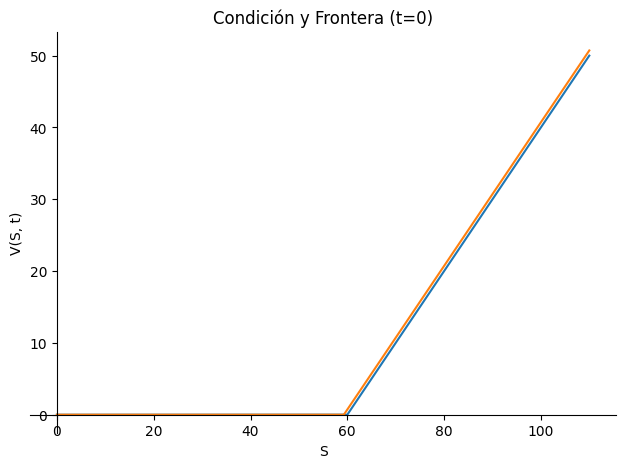

In [ ]:
#Grafico
sp.plot(
    cond_terminal.subs(datos),
    sp.Max(0, frontera_inf.subs(datos).subs(t, 0)),
    (S, 0, 110),
    title='Condición y Frontera (t=0)',
    xlabel='S',
    ylabel='V(S, t)',
)

La solución se obtiene siguiendo los pasos:

1. **Transformación del tiempo** $t \in [0, T]$ de tal manera que fluya en la dirección opuesta, desde el tiempo de expiración $T$ hasta $t = 0$. Para ello, hacemos $\tau = T - t$, $dt = -d\tau$ y reescribimos la ecuación (1) junto con sus condiciones.


In [ ]:
#TRANSFORMACIÓN DEL TIEMPO
tau = sp.Symbol('tau', real=True, positive=True)
W = sp.Function('W')(S, tau)

#Procedimiento
p1 = edp.subs({
    sp.diff(V, t): -sp.diff(W, tau),
    sp.diff(V, S, 2): sp.diff(W, S, 2),
    sp.diff(V, S): sp.diff(W, S),
    V: W,
})

#Despeje
p1 = sp.expand(-p1)

print("Ecuacion Diferencial Parcial Transformada en el Tiempo")
display(sp.Eq(p1, 0, evaluate=False))
display(sp.Eq(p1.subs(datos), 0, evaluate=False))

Ecuacion Diferencial Parcial Transformada en el Tiempo


                                                       2                       ↪
                                                 2  2 ∂                        ↪
                                                S ⋅σ ⋅───(W(S, τ))             ↪
                                                        2                      ↪
                ∂                 ∂                   ∂S             ∂         ↪
r⋅W(S, τ) + q⋅S⋅──(W(S, τ)) - S⋅r⋅──(W(S, τ)) - ────────────────── + ──(W(S, τ ↪
                ∂S                ∂S                    2            ∂τ        ↪

↪       
↪       
↪       
↪       
↪       
↪ )) = 0
↪       

                                                2                            
                      ∂                      2 ∂              ∂              
0.04⋅W(S, τ) - 0.04⋅S⋅──(W(S, τ)) - 0.04205⋅S ⋅───(W(S, τ)) + ──(W(S, τ)) = 0
                      ∂S                         2            ∂τ             
                                               ∂S                            

2. **Transformación logarítmica del precio de la acción subyacente**, con la sustitución $S = e^x$, $x = \ln S$ e introducción de la nueva función

$$Z(x, \tau) = W(e^x, \tau) \text{ y por ende } W(S, \tau) = Z(\ln S, \tau).$$

Notar que $S \in (0, \infty)$ si y solo si $x \in (-\infty, \infty)$. Usar la regla de la cadena para reescribir la ecuación obtenida en el Paso 1 para $Z(x, 0) = \overline{V}(e^x)$, $-\infty < x < \infty, \, \tau \in [0, T]$.

In [ ]:
# TRANSFORMACIÓN LOGARÍTMICA
x = sp.Symbol('x', real=True)
Z_func = sp.Function('Z')

#Definimos
W_compuesta = Z_func(sp.ln(S), tau)

#Regla de la cadena
edp_p2 = (
    -sp.diff(W_compuesta, tau)
    + sp.Rational(1, 2) * sigma**2 * S**2 * sp.diff(W_compuesta, S, 2)
    + (r - q) * S * sp.diff(W_compuesta, S)
    - r * W_compuesta
)

#Sustituir
Z = Z_func(x, tau)
edp_p2_l = sp.expand(-edp_p2.subs(sp.ln(S), x)).doit()
edp_p2_l = sp.collect(edp_p2_l, [sp.diff(Z, tau), sp.diff(Z, x, 2), sp.diff(Z, x), Z])

#Definir
lado_izq_Z = sp.diff(Z, tau)
lado_der_Z = sp.collect(sp.expand(lado_izq_Z - edp_p2_l), [sp.diff(Z, x, 2), sp.diff(Z, x), Z])
lado_der_Z_ej5 = lado_der_Z.subs(datos)

cond_inicial_Z = sp.Piecewise((sp.exp(x) - E, x >= sp.ln(E)), (0, True))

print('RESULTADO')
display(sp.Eq(edp_p2_l, 0))
print()
display(sp.Eq(edp_p2_l.subs(datos), 0))
print()
print('ECUACIÓN DIFERENCIAL PARCIAL CON COEFICIENTES CONSTANTES')
display(sp.Eq(lado_izq_Z, lado_der_Z_ej5))
print()
print('NUEVA CONDICIÓN INICIAL')
display(sp.Eq(sp.Function('Z')(x, 0), cond_inicial_Z.subs(datos)))

RESULTADO


                                           2                            
                                        2 ∂                             
                                       σ ⋅───(Z(x, τ))                  
            ⎛     2    ⎞                    2                           
            ⎜    σ     ⎟ ∂                ∂x             ∂              
r⋅Z(x, τ) + ⎜q + ── - r⎟⋅──(Z(x, τ)) - ─────────────── + ──(Z(x, τ)) = 0
            ⎝    2     ⎠ ∂x                   2          ∂τ             

                                              2                            
        ∂                                    ∂              ∂              
0.00205⋅──(Z(x, τ)) + 0.04⋅Z(x, τ) - 0.04205⋅───(Z(x, τ)) + ──(Z(x, τ)) = 0
        ∂x                                     2            ∂τ             
                                             ∂x                            


ECUACIÓN DIFERENCIAL PARCIAL CON COEFICIENTES CONSTANTES


                       2                                               
∂                     ∂                      ∂                         
──(Z(x, τ)) = 0.04205⋅───(Z(x, τ)) - 0.00205⋅──(Z(x, τ)) - 0.04⋅Z(x, τ)
∂τ                      2                    ∂x                        
                      ∂x                                               


NUEVA CONDICIÓN INICIAL


          ⎧       x                 
          ⎪-60 + ℯ   for x ≥ log(60)
Z(x, 0) = ⎨                         
          ⎪   0         otherwise   
          ⎩                         

3. **Transformación a la ecuación en derivadas parciales parabólica (2).** Los términos que contienen las derivadas de orden inferior $Z$ y $\frac{\partial Z}{\partial x}$ pueden eliminarse de la ecuación obtenida en el Paso 2 mediante una transformación exponencial

$$u(x, \tau) = e^{\alpha x + \beta \tau} Z(x, \tau), \quad \text{i.e.} \quad Z(x, \tau) = e^{-\alpha x - \beta \tau} u(x, \tau),$$

donde las constantes $\alpha, \beta$ se elijen de modo que la transformación de la ecuación corresponda a la forma (2).


In [ ]:
#TRANSFORMACION EXPONENCIAL
alpha, beta = sp.symbols('alpha beta', real=True)
u = sp.Function('u')(x, tau)

Z_exp = sp.exp(-alpha * x - beta * tau) * u
edp_p3 = sp.expand(
    edp_p2_l.subs(Z, Z_exp).doit() / sp.exp(-alpha * x - beta * tau))

#Resolver
sol_ab = sp.solve(
    [edp_p3.coeff(sp.diff(u, x)), edp_p3.coeff(u)], (alpha, beta))
sol_dict = dict(zip((alpha, beta), sol_ab[0]))
edp_calor = sp.simplify(edp_p3.subs(sol_dict))

#Valores
a2_num = (sp.Rational(1, 2) * sigma**2).subs(datos)
alpha_num = sol_dict[alpha].subs(datos).evalf(6)
beta_num = sol_dict[beta].subs(datos).evalf(6)

#Evaluar
x0 = sp.ln(58.5)
tau0 = datos[T]
factor_exp = sp.exp(-alpha * x - beta * tau).subs(sol_dict).subs(datos)
factor_val = factor_exp.subs({x: x0, tau: tau0}).evalf(7)

print('ALPHA')
display(sp.Eq(alpha, alpha_num))
print()
print('BETA')
display(sp.Eq(beta, beta_num))
print()
print('ECUACIÓN EN DERIVADAS PARCIALES PARABÓLICAS')
display(sp.Eq(edp_calor, 0))
print()
print('FACTOR DE EXPONENCIAL')
display(sp.Eq(factor_exp, factor_val))
print()
print('CONDICIÓN INICIAL')
display(sp.Eq(sp.Function('u')(x, 0), cond_inicial_Z.subs(datos)))

ALPHA


α = -0.0243802


BETA


β = 0.0400248


ECUACIÓN EN DERIVADAS PARCIALES PARABÓLICAS


      2                            
   2 ∂                             
  σ ⋅───(u(x, τ))                  
       2                           
     ∂x             ∂              
- ─────────────── + ──(u(x, τ)) = 0
         2          ∂τ             


FACTOR DE EXPONENCIAL


 0.02438⋅x - 0.04002⋅τ           
ℯ                      = 1.091114


CONDICIÓN INICIAL


          ⎧       x                 
          ⎪-60 + ℯ   for x ≥ log(60)
u(x, 0) = ⎨                         
          ⎪   0         otherwise   
          ⎩                         

4. **Aplicación de la fórmula de Green para obtener una solución de la ecuación del calor.** La fórmula explícita tiene la forma de una integral:

$$u(x, \tau) = \frac{1}{\sqrt{2\sigma^2 \pi \tau}} \int_{-\infty}^{\infty} e^{-\frac{(x - s)^2}{2\sigma^2 \tau}} u(s, 0) \, ds.$$

Ahora, por una secuencia de sustituciones hacia atrás $u \longmapsto Z \longmapsto W \longmapsto V$ obtenemos finalmente:

$$V(S, T - \tau) = e^{-\beta \tau} e^{-\alpha \ln S} u(\ln S, \tau),$$

y entonces

$$V(S, T - \tau) = \frac{e^{-\beta \tau}}{\sqrt{2\sigma^2 \pi \tau}} S^{-\alpha} \int_{-\infty}^{\infty} e^{-\frac{(\ln S - s)^2}{2\sigma^2 \tau}} e^{\alpha s} \overline{V}(e^s) \, ds. \quad (3)$$



In [ ]:
#FÓRMULA DE GREEN
s = sp.Symbol('s', real=True)
V_final = sp.Function('V')(S, t)

#Solucion
u_s0 = cond_u0.subs(x, s)
integrando_green = sp.exp(-((x - s) ** 2) / (2 * sigma**2 * tau)) * u_s0
u_green = (1 / sp.sqrt(2 * sigma**2 * sp.pi * tau)) * sp.Integral(
    integrando_green, (s, -sp.oo, sp.oo))

#Sustitucion
V_ec3 = (sp.exp(-beta * tau) * S ** (-alpha) * u_green.subs(x, sp.ln(S))).subs(sol_ab)

N_cdf = lambda d: sp.Rational(1, 2) * (1 + sp.erf(d / sp.sqrt(2)))

d1 = (sp.ln(S / E) + (r - q + sp.Rational(1, 2) * sigma**2) * (T - t)) / (sigma * sp.sqrt(T - t))
d2 = d1 - sigma * sp.sqrt(T - t)

V_bs = S * sp.exp(-q * (T - t)) * N_cdf(d1) - E * sp.exp(-r * (T - t)) * N_cdf(d2)

print('FÓRMULA DE GREEN')
display(sp.Eq(u, u_green))

print('ECUACIÓN (3)')
display(sp.Eq(sp.Function('V')(S, T - tau), V_ec3))

print('FÓRMULA DE BLACK-SCHOLES')
display(sp.Eq(V_final, V_bs))

print('EVALUACIÓN NUMÉRICA DEL EJERCICIO')
precio_ibm = V_bs.subs(datos).subs({S: sp.Float('58.5', 6), t: 0}).evalf(6)
display(sp.Eq(sp.Function('V')(58.5, 0), precio_ibm))

FÓRMULA DE GREEN


             ∞                                                                 
             ⌠                                                                 
             ⎮  ⎧              ⎛ 2            ⎞           2                    
             ⎮  ⎪           -s⋅⎝σ  - 2⋅r + 2⋅q⎠   -(x - s)                     
             ⎮  ⎪           ────────────────────  ──────────                   
             ⎮  ⎪                      2               2                       
          √2⋅⎮  ⎨⎛      s⎞          2⋅σ             2⋅σ ⋅τ                   ds
             ⎮  ⎪⎝-E + ℯ ⎠⋅ℯ                    ⋅ℯ            for s ≥ log(E)   
             ⎮  ⎪                                                              
             ⎮  ⎪                     0                         otherwise      
             ⎮  ⎩                                                              
             ⌡                                                                 
             -∞                         

ECUACIÓN (3)


                     ∞                                                         ↪
                     ⌠                                                         ↪
                     ⎮  ⎧                         2     ⎛ 4      2      2      ↪
                     ⎮  ⎪           -(-s + log(S))    s⋅⎝σ  + 4⋅q  + 4⋅r  - 8⋅ ↪
                     ⎮  ⎪           ────────────────  ──────────────────────── ↪
                  -α ⎮  ⎪                   2                                  ↪
              √2⋅S  ⋅⎮  ⎨⎛      s⎞       2⋅σ ⋅τ                            8⋅σ ↪
                     ⎮  ⎪⎝-E + ℯ ⎠⋅ℯ                ⋅ℯ                         ↪
                     ⎮  ⎪                                                      ↪
                     ⎮  ⎪                                     0                ↪
                     ⎮  ⎩                                                      ↪
                     ⌡                                                         ↪
                     -∞     

FÓRMULA DE BLACK-SCHOLES


                                                                          ⎛    ↪
                                                                          ⎜    ↪
            ⎛       ⎛   ⎛        ⎛     2    ⎞         ⎞⎞⎞                 ⎜    ↪
            ⎜       ⎜   ⎜        ⎜    σ     ⎟      ⎛S⎞⎟⎟⎟                 ⎜    ↪
            ⎜       ⎜√2⋅⎜(T - t)⋅⎜r + ── - q⎟ + log⎜─⎟⎟⎟⎟                 ⎜    ↪
            ⎜       ⎜   ⎝        ⎝    2     ⎠      ⎝E⎠⎠⎟⎟                 ⎜    ↪
            ⎜    erf⎜──────────────────────────────────⎟⎟                 ⎜    ↪
            ⎜       ⎜                _______           ⎟⎟                 ⎜    ↪
            ⎜1      ⎝          2⋅σ⋅╲╱ T - t            ⎠⎟  -q⋅(T - t)     ⎜1   ↪
V(S, t) = S⋅⎜─ + ───────────────────────────────────────⎟⋅ℯ           - E⋅⎜─ + ↪
            ⎝2                      2                   ⎠                 ⎝2   ↪

↪     ⎛   ⎛                        ⎛     2    ⎞         ⎞⎞⎞            
↪     ⎜   ⎜                        ⎜

EVALUACIÓN NUMÉRICA DEL EJERCICIO


V(58.5, 0) = 3.34893

<h1> Grafica en 3D </h1>

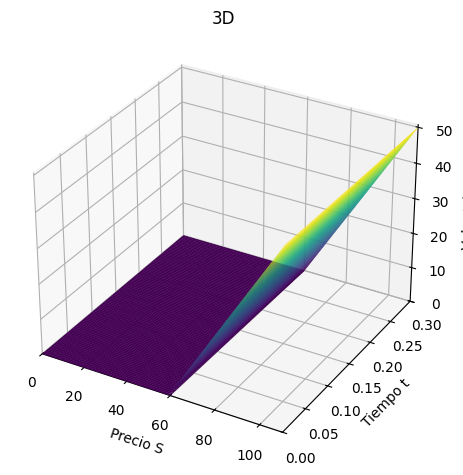

In [ ]:
from sympy.plotting import plot3d

sup_terminal = cond_terminal.subs(datos)
sup_frontera = sp.Max(0, frontera_inf.subs(datos))

plot3d(
    (sup_terminal, (S, 0, 110), (t, 0, 0.3)),
    (sup_frontera, (S, 0, 110), (t, 0, 0.3)),
    title='3D',
    xlabel='Precio S',
    ylabel='Tiempo t',
    zlabel='Valor V(S, t)',)